## Measurable image-processing pipeline: background removal, then brick separation
Stage 1 `foreground` (plain background -> tower mask, GrabCut). Stage 2 `separate` (edges + watershed -> one label per brick).
Measured on rendered towers with exact masks, on 3 background colors, with an **oracle foreground** run so a stage-1 error and a stage-2 error are not mixed up.
Metrics: foreground IoU, PQ = SQ x RQ (matched at IoU > 0.5), merges (one predicted blob covering 2+ real bricks, the SAM failure).

**What this notebook does.** Tests a classic image-processing pipeline with no learned detector, in two measurable stages: (1) **foreground**, which separates the tower from the background, and (2) **separate**, which splits the tower into one region per brick using edges and watershed. It is scored on rendered towers with exact masks, run on the real photos, and every piece found is named with the gallery lookup.

**Needs:** `ldraw/`, `real/`, `data/gallery.npz`, optionally `models/birefnet_lite.onnx` + `onnxruntime`. **Writes:** figures to `output/`.

Minimal imports. Run only this cell if you just want the real-photo test (cell 2b), not the renders.

In [1]:
import cv2, numpy as np, matplotlib.pyplot as plt   # run this first if you only want the real-photo test (skips the render cell)

Build the test scenes: 12 rendered towers, each on 3 plain backgrounds (gray, green, blue), with blur and noise like a camera.

In [2]:
# 1. Test scenes: rendered towers (exact brick masks) on a plain background, near-orthographic camera from the front, camera-like blur and noise.
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
import csv, sys, cv2, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '.'); import ldraw_render as R

ld = {r['bricklink_name']: int(r['ldraw_code']) for r in csv.DictReader(open('data/lego_colors.csv'))}
PARTS = []
for r in csv.DictReader(open('data/element_map.csv')):
    try: R.flatten(r['part_num'] + '.dat'); PARTS.append((r['part_num'], ld[r['color']]))
    except (FileNotFoundError, KeyError): pass
BGS = {'gray': (150, 150, 150), 'green': (30, 150, 70), 'blue': (40, 80, 170)}   # gray is the hardest (light-gray bricks); green/blue are colors no brick has
N = 12

def build(seed):   # same tower + camera for every background, so the backgrounds are compared fairly
    rng = np.random.default_rng(seed); tower = R.make_tower(PARTS, rng, plate=True)
    return R.render_scene(tower, size=800, rng=rng, az=rng.uniform(-.15, .15), el=rng.uniform(.1, .5), fov=rng.uniform(10, 25), zoom=rng.uniform(.6, .8))

def compose(rgba, rng, bgc):
    S = rgba.shape[0]; a = rgba[..., 3:] / 255.0
    bg = np.array(bgc, float) * (0.85 + 0.3 * np.linspace(0, 1, S)[:, None, None] * rng.uniform(.5, 1)) * np.ones((S, S, 3))   # soft light gradient
    sh = cv2.GaussianBlur(np.roll(a[..., 0], (int(rng.integers(8, 30)), int(rng.integers(-20, 20))), (0, 1)), (0, 0), 12)[..., None]
    im = (bg * (1 - 0.35 * sh)) * (1 - a) + rgba[..., :3] * a
    im = cv2.GaussianBlur(im * rng.uniform(0.85, 1.15), (0, 0), 0.7)
    return np.clip(im + rng.normal(0, 3, im.shape), 0, 255).astype(np.uint8)

SCENES = {k: [] for k in BGS}
for s in range(N):
    rgba, ids = build(s)
    for k, c in BGS.items(): SCENES[k].append((compose(rgba, np.random.default_rng([s, 7]), c), ids))
print(N, 'towers x', len(BGS), 'backgrounds')

12 towers x 3 backgrounds


**Result:** 12 towers x 3 backgrounds, each with an exact brick mask to score against.

In [3]:
# 2. The pipeline: two stages, each a plain function of the image, so each can be swapped for a better one and re-measured.
K3 = np.ones((3, 3), np.uint8)

def foreground(im):
    """Stage 1: plain background -> tower mask (uint8 0/1). Seeds from the colour distance to the border, then GrabCut refines it.
    shortcut: assumes the border is background and the tower does not touch it; upgrade to a learned matting model (BiRefNet) if real backgrounds are busy."""
    lab = cv2.cvtColor(im, cv2.COLOR_RGB2LAB).astype(np.float32)
    border = np.concatenate([lab[:10].reshape(-1, 3), lab[-10:].reshape(-1, 3), lab[:, :10].reshape(-1, 3), lab[:, -10:].reshape(-1, 3)])
    d = np.linalg.norm(lab - np.median(border, 0), axis=2)
    gc = np.full(d.shape, cv2.GC_PR_BGD, np.uint8); gc[d > 18] = cv2.GC_PR_FGD; gc[d > 45] = cv2.GC_FGD; gc[d < 6] = cv2.GC_BGD
    gc[:10], gc[-10:], gc[:, :10], gc[:, -10:] = cv2.GC_BGD, cv2.GC_BGD, cv2.GC_BGD, cv2.GC_BGD
    if not (gc == cv2.GC_FGD).any(): return np.zeros(d.shape, np.uint8)
    cv2.grabCut(im[..., ::-1].copy(), gc, None, np.zeros((1, 65)), np.zeros((1, 65)), 3, cv2.GC_INIT_WITH_MASK)
    fg = ((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD)).astype(np.uint8)
    n, lbl, st, _ = cv2.connectedComponentsWithStats(fg)   # keep the biggest blob only
    return (lbl == 1 + st[1:, cv2.CC_STAT_AREA].argmax()).astype(np.uint8) if n > 1 else fg

def edge_map(im, canny=(30, 90), ab=(10, 30), dark=14):
    """Seams from 3 cues: Canny on L (light/dark steps), Canny on Lab a and b (tan vs white vs gray have the same L but not the same colour),
    and a black-hat on L (thin dark lines: the shadow in a seam). Bilateral first: it smooths studs and print but keeps seams sharp."""
    lab = cv2.cvtColor(cv2.bilateralFilter(im, 7, 25, 7), cv2.COLOR_RGB2LAB)
    e = cv2.Canny(cv2.GaussianBlur(lab[..., 0], (0, 0), 1.2), *canny)
    for c in (1, 2): e |= cv2.Canny(cv2.GaussianBlur(lab[..., c], (0, 0), 1.2), *ab)
    return e | ((cv2.morphologyEx(lab[..., 0], cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))) > dark).astype(np.uint8) * 255)

def separate(im, fg, canny=(30, 90), ab=(10, 30), dark=14, erode=2, min_seed=40):
    """Stage 2: split the tower mask into bricks. Brick faces are flat and bounded by edges (the seams and shadows between bricks), so:
    mask minus edges = one seed per face, then watershed grows the seeds back to the mask. -> int label image, 0 = background, 1..K = bricks.
    shortcut: a same-colored seam with no visible edge stays merged; the stud grid (known width) is the next cue to add."""
    edges = cv2.dilate(edge_map(im, canny, ab, dark), K3)
    core = cv2.erode(((fg > 0) & (edges == 0)).astype(np.uint8), K3, iterations=erode)
    n, seeds = cv2.connectedComponents(core); area = np.bincount(seeds.ravel(), minlength=n)
    markers = np.zeros(fg.shape, np.int32); markers[cv2.erode((fg == 0).astype(np.uint8), K3, iterations=2) > 0] = 1
    k = 2
    for i in range(1, n):
        if area[i] >= min_seed: markers[seeds == i] = k; k += 1
    cv2.watershed(im[..., ::-1].copy(), markers)
    out = np.where((markers >= 2) & (fg > 0), markers - 1, 0).astype(np.int32)
    return out

**Result:** `foreground()` and `separate()` are defined. Each stage is a plain function, so it can be swapped out and measured again.

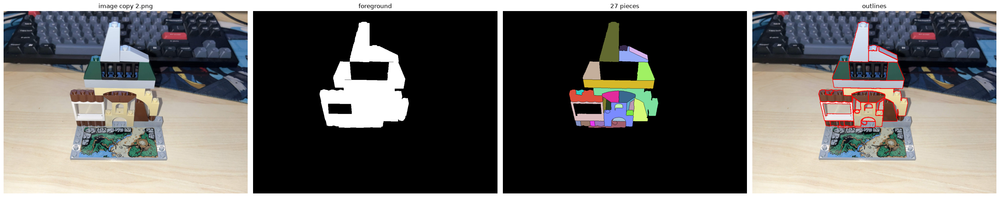

saved output/image_copy_2_{outlines,pieces,labels,pipeline}.png


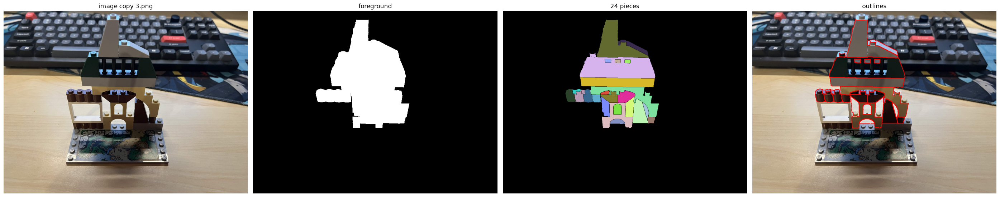

saved output/image_copy_3_{outlines,pieces,labels,pipeline}.png


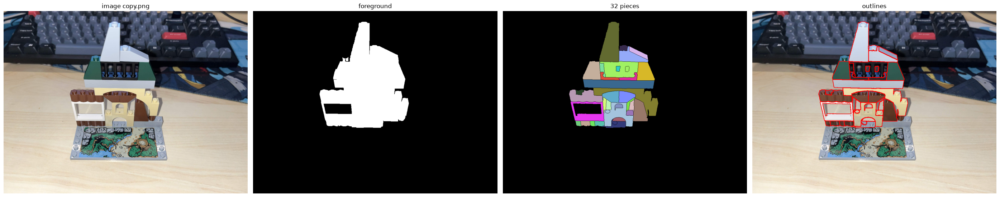

saved output/image_copy_{outlines,pieces,labels,pipeline}.png


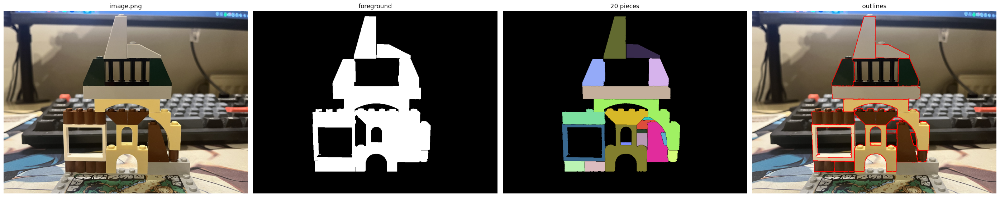

saved output/image_{outlines,pieces,labels,pipeline}.png


In [4]:
# 2b. REAL PHOTO TEST (no renders needed: run the imports cell, cell 2, then this one). Everything is also saved to output/.
# Your photos have a busy background (keyboard, mat), so stage 1 cannot assume a plain border. Instead GrabCut starts from rectangles around the tower
# (everything outside = background). RECT per photo = one rectangle or a LIST of rectangles (x0, y0, x1, y1), as fractions of the width/height; a list lets the
# allowed region follow the tower's stepped shape (narrow roof on top, wide body below). It ENDS ABOVE THE BASE PLATE: the plate is a known object
# and its printed picture otherwise splits into ~20 fake bricks.
import os, glob
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')
os.makedirs('output', exist_ok=True)
RECT = {'default': (0.25, 0.04, 0.68, 0.64),   # the 'image copy' photos (view from above)
        'image.png': [(0.32, 0.02, 0.68, 0.45), (0.23, 0.42, 0.78, 0.88)]}   # the level close-up: roof on top, wide body below
MIN_AREA = 300    # px at 1000 px wide: a piece smaller than this is a fragment (a stud, a glare spot) and is merged into the neighbour it touches most
HOLE = 1500       # px: a hole in the tower mask smaller than this is filled (the black window bars); bigger holes (arches, windows) stay open

def foreground_rect(im, rects):
    h, w = im.shape[:2]; gc = np.full((h, w), cv2.GC_BGD, np.uint8)
    for x0, y0, x1, y1 in (rects if isinstance(rects[0], (tuple, list)) else [rects]): gc[int(y0 * h):int(y1 * h), int(x0 * w):int(x1 * w)] = cv2.GC_PR_FGD
    cv2.grabCut(im[..., ::-1].copy(), gc, None, np.zeros((1, 65)), np.zeros((1, 65)), 5, cv2.GC_INIT_WITH_MASK)
    fg = ((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD)).astype(np.uint8)
    n, lbl, st, _ = cv2.connectedComponentsWithStats(fg)   # keep the biggest blob only: drops the stray key / cable blobs
    if n > 1: fg = (lbl == 1 + st[1:, cv2.CC_STAT_AREA].argmax()).astype(np.uint8)
    cs, hier = cv2.findContours(fg, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    for c, hh in zip(cs, hier[0]):   # fill small holes
        if hh[3] >= 0 and cv2.contourArea(c) < HOLE: cv2.drawContours(fg, [c], -1, 1, -1)
    return fg

def cleanup(lab, min_area=MIN_AREA):
    """Post-step: merge fragments into the neighbour they share the longest border with, then renumber 1..K."""
    lab = lab.copy()
    for i, a in sorted(enumerate(np.bincount(lab.ravel())), key=lambda t: t[1]):
        if i == 0 or a == 0 or a >= min_area: continue
        m = lab == i; nb = lab[(cv2.dilate(m.astype(np.uint8), K3, iterations=2) > 0) & ~m]; nb = nb[(nb > 0) & (nb != i)]
        lab[m] = np.bincount(nb).argmax() if len(nb) else 0
    u, inv = np.unique(lab, return_inverse=True); return (inv.reshape(lab.shape) + (0 if u[0] == 0 else 1)).astype(np.int32)

def colorize(lab, seed=0):
    lut = np.random.default_rng(seed).integers(40, 255, (int(lab.max()) + 1, 3)); lut[0] = 0; return lut[lab].astype(np.uint8)

for f in sorted(glob.glob('real/*.[jJpP][pPnN]*[gG]')):
    name = os.path.splitext(os.path.basename(f))[0].replace(' ', '_')
    im = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); im = cv2.resize(im, (1000, int(1000 * im.shape[0] / im.shape[1])))
    fg = foreground_rect(im, RECT.get(os.path.basename(f), RECT['default'])); pred = cleanup(separate(im, fg))
    over = im.copy(); over[cv2.morphologyEx(pred.astype(np.float32), cv2.MORPH_GRADIENT, K3) > 0] = (255, 0, 0)
    cv2.imwrite(f'output/{name}_outlines.png', over[..., ::-1]); cv2.imwrite(f'output/{name}_pieces.png', colorize(pred)[..., ::-1])
    cv2.imwrite(f'output/{name}_labels.png', pred.astype(np.uint16))   # 16-bit label image: pixel value = piece number, 0 = background
    fig, ax = plt.subplots(1, 4, figsize=(28, 7))
    for a, x, t in zip(ax, (im, fg * 255, colorize(pred), over), (os.path.basename(f), 'foreground', f'{pred.max()} pieces', 'outlines')): a.imshow(x, cmap='gray'); a.set_title(t); a.axis('off')
    plt.tight_layout(); fig.savefig(f'output/{name}_pipeline.png', dpi=60, bbox_inches='tight'); plt.show()
    print('saved output/' + name + '_{outlines,pieces,labels,pipeline}.png')

**Result:** Every real photo is split into pieces and saved to `output/`. Check the outlines: real bricks should be separate regions, and the base plate should stay out.

foreground: BiRefNet-lite model


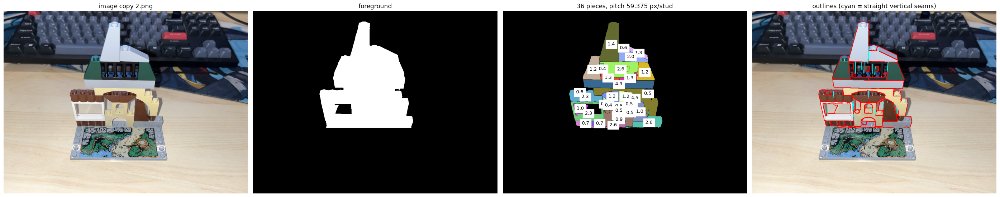

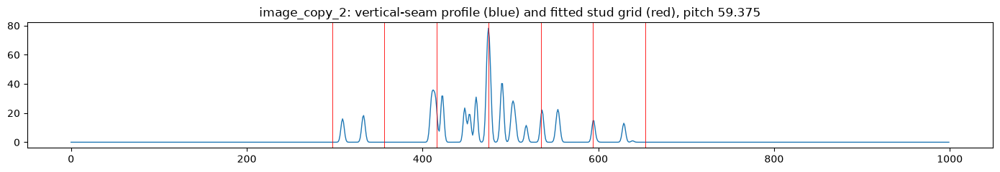

image_copy_2 -> 36 pieces, stud pitch 59.375 px; saved output/image_copy_2_v2_*.png


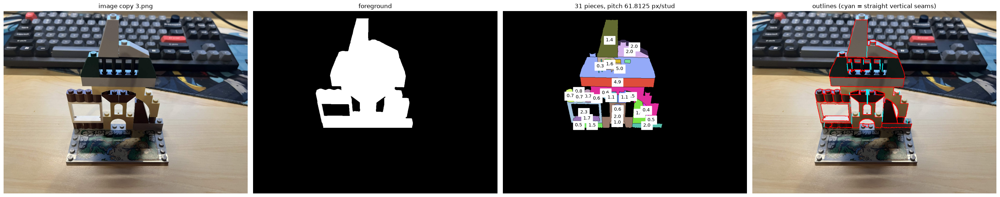

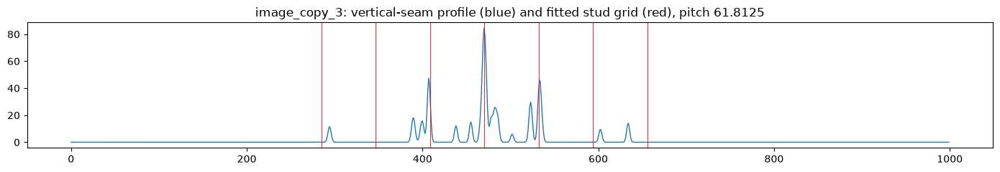

image_copy_3 -> 31 pieces, stud pitch 61.8125 px; saved output/image_copy_3_v2_*.png


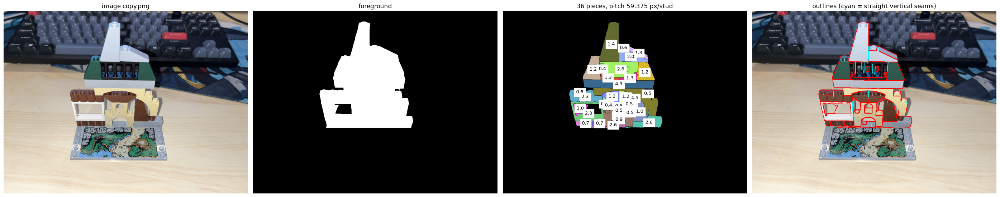

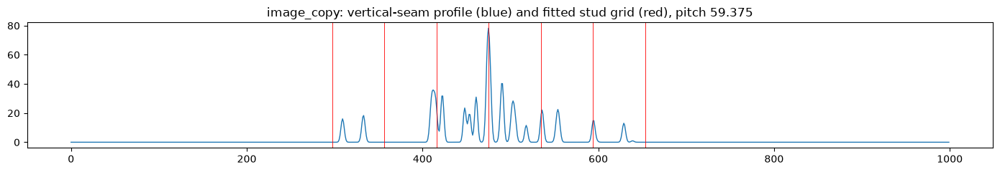

image_copy -> 36 pieces, stud pitch 59.375 px; saved output/image_copy_v2_*.png


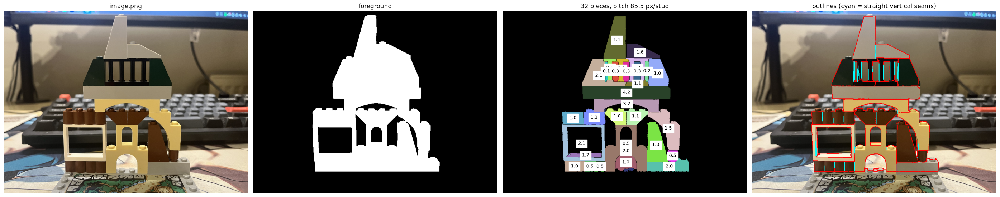

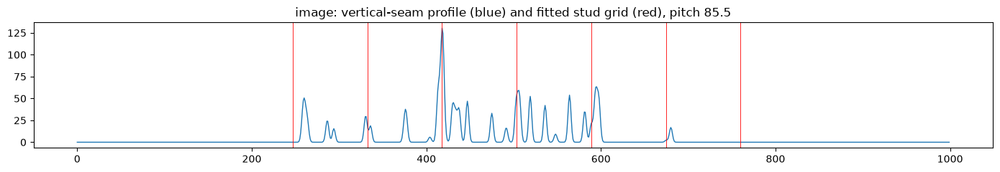

image -> 32 pieces, stud pitch 85.5 px; saved output/image_v2_*.png


In [5]:
# 2c. THE THREE UPGRADES on the real photos (run after 2b: reuses its RECT, cleanup, colorize, foreground_rect).
# 1) foreground from a salient-object model (BiRefNet-lite ONNX) if models/birefnet_lite.onnx + onnxruntime exist, else the GrabCut rectangles from 2b.
# 2) stud pitch: brick seams sit on the stud grid, so the pitch is the comb spacing that best fits the vertical seams; each piece's width is then printed in studs.
# 3) straight seams: Hough lines kept only if horizontal/vertical (+-6 deg) are added to the edge map, so faint but straight seams still split bricks.
MODEL = 'models/birefnet_lite.onnx'   # you download this one (onnx-community/BiRefNet_lite-ONNX on Hugging Face), then pip-install onnxruntime
try:
    import onnxruntime as ort
    SESS = ort.InferenceSession(MODEL, providers=['CPUExecutionProvider']) if os.path.exists(MODEL) else None
    why = '' if SESS else f'{MODEL} not found (cwd {os.getcwd()})'
except ImportError: SESS, why = None, 'onnxruntime is not installed in this kernel'
print('foreground:', 'BiRefNet-lite model' if SESS else 'GrabCut rectangles: ' + why)

def rect_mask(shape, rects):
    m = np.zeros(shape[:2], np.uint8); h, w = shape[:2]
    for x0, y0, x1, y1 in (rects if isinstance(rects[0], (tuple, list)) else [rects]): m[int(y0 * h):int(y1 * h), int(x0 * w):int(x1 * w)] = 1
    return m

def tidy(fg):   # biggest blob only, small holes filled (same as in foreground_rect)
    n, lbl, st, _ = cv2.connectedComponentsWithStats(fg)
    if n > 1: fg = (lbl == 1 + st[1:, cv2.CC_STAT_AREA].argmax()).astype(np.uint8)
    cs, hier = cv2.findContours(fg, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    for c, hh in zip(cs, hier[0]):
        if hh[3] >= 0 and cv2.contourArea(c) < HOLE: cv2.drawContours(fg, [c], -1, 1, -1)
    return fg

def foreground_v2(im, rects):
    if SESS is None: return foreground_rect(im, rects)
    h, w = im.shape[:2]; x = (cv2.resize(im, (1024, 1024)).astype(np.float32) / 255 - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
    logit = SESS.run(None, {SESS.get_inputs()[0].name: x.transpose(2, 0, 1)[None].astype(np.float32)})[-1][0, 0]
    fg = (cv2.resize(1 / (1 + np.exp(-logit)), (w, h)) > 0.5).astype(np.uint8) * rect_mask(im.shape, rects)   # the rectangles still cut the base plate off
    return tidy(fg)

def seam_lines(im, fg, tol=6, min_len=20, votes=20):
    """Straight, axis-aligned line segments inside the tower -> (vertical mask, horizontal mask), uint8 0/255.
    More sensitive than before (fewer votes, shorter lines): seams between 1-stud bricks are short."""
    e = cv2.Canny(cv2.GaussianBlur(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY), (0, 0), 1.0), 15, 45)
    L = cv2.HoughLinesP(e, 1, np.pi / 360, votes, minLineLength=min_len, maxLineGap=6)
    v, hz = np.zeros(fg.shape, np.uint8), np.zeros(fg.shape, np.uint8)
    for x1, y1, x2, y2 in ([] if L is None else L.reshape(-1, 4)):   # reshape: OpenCV versions return (N,1,4) or (N,4)
        a = np.degrees(np.arctan2(y2 - y1, x2 - x1)) % 180
        if min(a, 180 - a) < tol: cv2.line(hz, (int(x1), int(y1)), (int(x2), int(y2)), 255, 2)
        elif abs(a - 90) < tol: cv2.line(v, (int(x1), int(y1)), (int(x2), int(y2)), 255, 2)
    inside = cv2.erode(fg, K3, iterations=3) * 255   # shortcut: lines on the tower outline are dropped with the border
    return v & inside, hz & inside

def stud_pitch(vseam, fg):
    """Pixels per stud -> (pitch, seam profile). The comb spacing that best matches the vertical seams, searched only where it can be true:
    the tower is 6 to 16 studs wide (so pitch = width/16 .. width/6). shortcut: one pitch for the whole photo; perspective makes it vary with depth."""
    xs = np.where(fg.any(0))[0]
    if len(xs) < 50: return None, None
    lo, hi = xs.min(), xs.max(); prof = cv2.GaussianBlur((vseam.sum(0) / 255.).astype(np.float32)[None], (0, 0), 1.5)[0]; base = prof[lo:hi].mean()
    ps = np.arange(max(10, (hi - lo) / 16), (hi - lo) / 6, 0.5); sc = np.zeros(len(ps))
    if len(ps) == 0: return None, prof
    for j, p in enumerate(ps):
        ks = np.arange(0, hi - lo, p); sc[j] = max(prof[np.clip((lo + ph + ks).astype(int), 0, len(prof) - 1)].mean() for ph in range(int(p))) - base
    return (float(ps[np.argmax(sc >= 0.85 * sc.max())]) if sc.max() > 0 else None), prof   # smallest spacing that is almost as good as the best (not 2x, 3x ...)

def separate_v2(im, fg):
    v, hz = seam_lines(im, fg); edges = cv2.dilate(edge_map(im) | v | hz, K3)
    core = cv2.erode(((fg > 0) & (edges == 0)).astype(np.uint8), K3, iterations=2)
    n, seeds = cv2.connectedComponents(core); area = np.bincount(seeds.ravel(), minlength=n)
    markers = np.zeros(fg.shape, np.int32); markers[cv2.erode((fg == 0).astype(np.uint8), K3, iterations=2) > 0] = 1; k = 2
    for i in range(1, n):
        if area[i] >= 40: markers[seeds == i] = k; k += 1
    cv2.watershed(im[..., ::-1].copy(), markers)
    return np.where((markers >= 2) & (fg > 0), markers - 1, 0).astype(np.int32), v

for f in sorted(glob.glob('real/*.[jJpP][pPnN]*[gG]')):
    name = os.path.splitext(os.path.basename(f))[0].replace(' ', '_'); rects = RECT.get(os.path.basename(f), RECT['default'])
    im = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); im = cv2.resize(im, (1000, int(1000 * im.shape[0] / im.shape[1])))
    fg = foreground_v2(im, rects); lab, v = separate_v2(im, fg); pred = cleanup(lab); pitch, prof = stud_pitch(v, fg)
    over = im.copy(); over[cv2.morphologyEx(pred.astype(np.float32), cv2.MORPH_GRADIENT, K3) > 0] = (255, 0, 0); over[v > 0] = (0, 255, 255)   # cyan = vertical seams used
    cv2.imwrite(f'output/{name}_v2_outlines.png', over[..., ::-1]); cv2.imwrite(f'output/{name}_v2_labels.png', pred.astype(np.uint16))
    fig, ax = plt.subplots(1, 4, figsize=(28, 7))
    for a, x, t in zip(ax, (im, fg * 255, colorize(pred), over), (os.path.basename(f), 'foreground', f'{pred.max()} pieces, pitch {pitch} px/stud', 'outlines (cyan = straight vertical seams)')): a.imshow(x, cmap='gray'); a.set_title(t); a.axis('off')
    if pitch:
        for i in range(1, pred.max() + 1):
            ys, xs_ = np.where(pred == i)
            if len(xs_) > 400: ax[2].text(xs_.mean(), ys.mean(), f'{(xs_.max() - xs_.min() + 1) / pitch:.1f}', fontsize=9, color='black', backgroundcolor='white', ha='center', va='center')   # width in studs
    plt.tight_layout(); fig.savefig(f'output/{name}_v2_pipeline.png', dpi=60, bbox_inches='tight'); plt.show()
    if prof is not None:   # the seam profile with the fitted grid: peaks should line up with the red ticks. If there are no peaks, no pitch can be trusted.
        fig, a = plt.subplots(figsize=(14, 2.5)); a.plot(prof, lw=1); xs_ = np.where(fg.any(0))[0]
        if pitch:
            ph = max(range(int(pitch)), key=lambda q: prof[np.clip((xs_.min() + q + np.arange(0, xs_.max() - xs_.min(), pitch)).astype(int), 0, len(prof) - 1)].mean())
            for xx in xs_.min() + ph + np.arange(0, xs_.max() - xs_.min(), pitch): a.axvline(xx, color='r', lw=.6)
        a.set_title(f'{name}: vertical-seam profile (blue) and fitted stud grid (red), pitch {pitch}'); plt.tight_layout(); plt.show()
    print(name, '->', pred.max(), 'pieces, stud pitch', pitch, 'px; saved output/' + name + '_v2_*.png')

**Result:** With BiRefNet-lite as the foreground model, the photos split into 31-36 pieces, and the stud spacing is found (about 60 px, or 85 px on the close-up).

Memory fix: limit ONNX's memory use and run BiRefNet only once per photo, so the next cells don't run out of RAM.

In [6]:
# 2c-fix. MEMORY: run right after 2c. (1) the ONNX session gets a capped thread count and no memory arena (the arena keeps every 1024x1024 activation buffer and never gives it back),
# (2) BiRefNet runs ONCE per photo: the result is cached, so 2d/2e/2f no longer re-run it. Overrides SESS and foreground_v2 from 2c.
import gc
if SESS is not None:
    so = ort.SessionOptions(); so.enable_cpu_mem_arena = False; so.enable_mem_pattern = False; so.intra_op_num_threads = 4
    SESS = ort.InferenceSession(MODEL, so, providers=['CPUExecutionProvider'])
_FG = {}
def foreground_v2(im, rects):
    key = (im.shape, int(im[::37, ::37].sum()), str(rects))   # same photo + same rectangles -> same mask
    if key in _FG: return _FG[key].copy()
    if SESS is None: fg = foreground_rect(im, rects)
    else:
        h, w = im.shape[:2]; x = (cv2.resize(im, (1024, 1024)).astype(np.float32) / 255 - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
        logit = SESS.run(None, {SESS.get_inputs()[0].name: x.transpose(2, 0, 1)[None].astype(np.float32)})[-1][0, 0]
        fg = tidy((cv2.resize(1 / (1 + np.exp(-logit)), (w, h)) > 0.5).astype(np.uint8) * rect_mask(im.shape, rects)); del x, logit
    _FG[key] = fg; gc.collect(); return fg.copy()
plt.rcParams['figure.max_open_warning'] = 0   # figures are closed by plt.show() in the notebook; this only silences the warning
print('memory fix on: ONNX arena off, 4 threads, foreground cached')

memory fix on: ONNX arena off, 4 threads, foreground cached


**Result:** The fix is on. Later cells reuse the cached foreground masks.

kernel python: /home/denkata/Desktop/Lego Fusion Battle Towers Model/.venv/bin/python
model loaded: True
input: input_image [1, 3, 1024, 1024] tensor(float) | outputs: [('output_image', [1, 1, 1024, 1024])]
image copy 2.png | prob min/max 0.0 1.0 | pixels > 0.5: 151491


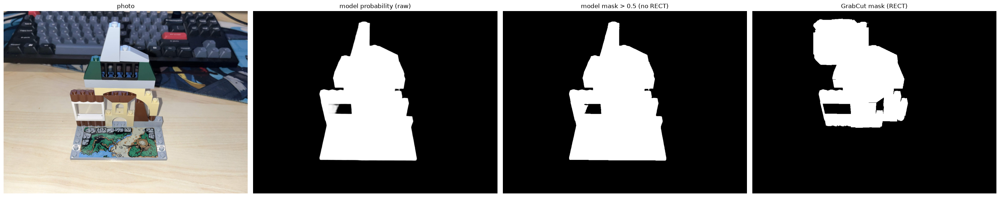

image copy 3.png | prob min/max 0.0 1.0 | pixels > 0.5: 163523


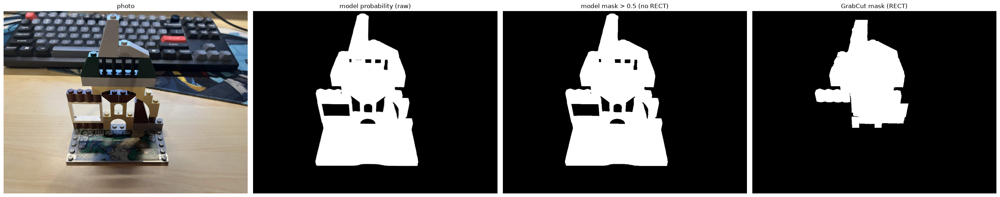

image copy.png | prob min/max 0.0 1.0 | pixels > 0.5: 151491


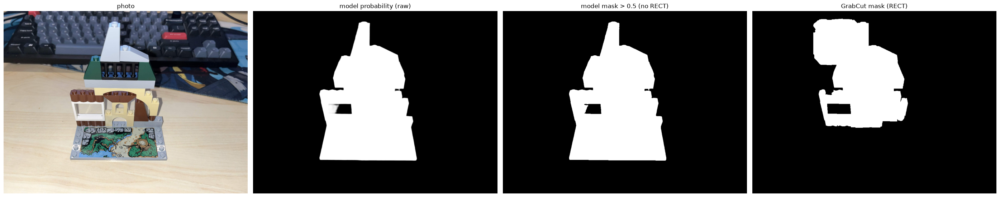

image.png | prob min/max 0.0 1.0 | pixels > 0.5: 227835


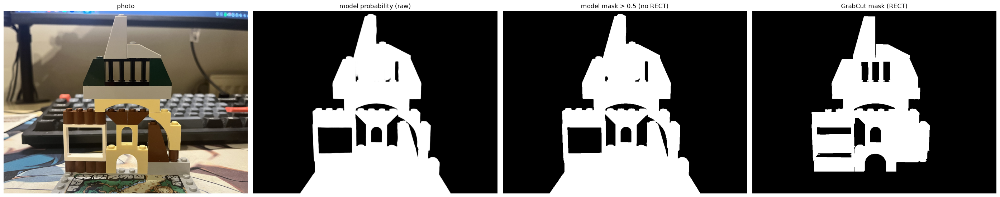

In [7]:
# 2d. DIAGNOSTIC: what does the BiRefNet model itself see? Raw probability map, no RECT, no cleanup, next to the GrabCut mask. Run after 2c.
import sys; print('kernel python:', sys.executable); print('model loaded:', SESS is not None)
if SESS is not None:
    print('input:', SESS.get_inputs()[0].name, SESS.get_inputs()[0].shape, SESS.get_inputs()[0].type, '| outputs:', [(o.name, o.shape) for o in SESS.get_outputs()])
    for f in sorted(glob.glob('real/*.[jJpP][pPnN]*[gG]')):
        im = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); im = cv2.resize(im, (1000, int(1000 * im.shape[0] / im.shape[1]))); h, w = im.shape[:2]
        x = (cv2.resize(im, (1024, 1024)).astype(np.float32) / 255 - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
        outs = SESS.run(None, {SESS.get_inputs()[0].name: x.transpose(2, 0, 1)[None].astype(np.float32)})
        p = cv2.resize(1 / (1 + np.exp(-outs[-1][0, 0])), (w, h)); print(os.path.basename(f), '| prob min/max', round(float(p.min()), 3), round(float(p.max()), 3), '| pixels > 0.5:', int((p > .5).sum()))
        fig, ax = plt.subplots(1, 4, figsize=(28, 7))
        for a, y, t in zip(ax, (im, p, p > .5, foreground_rect(im, RECT.get(os.path.basename(f), RECT['default']))), ('photo', 'model probability (raw)', 'model mask > 0.5 (no RECT)', 'GrabCut mask (RECT)')): a.imshow(y, cmap='gray'); a.set_title(t); a.axis('off')
        plt.tight_layout(); plt.show()

**Result:** The raw BiRefNet probability map, next to the GrabCut mask. Use it to see whether a mistake comes from the model or from the rectangles.

image copy 2.png: 33 pieces | named 14, unknown 19 | similarity median 0.84 | repeated part+colour: {(np.str_('3009'), np.str_('141')): 2, (np.str_('87552'), np.str_('5')): 2}


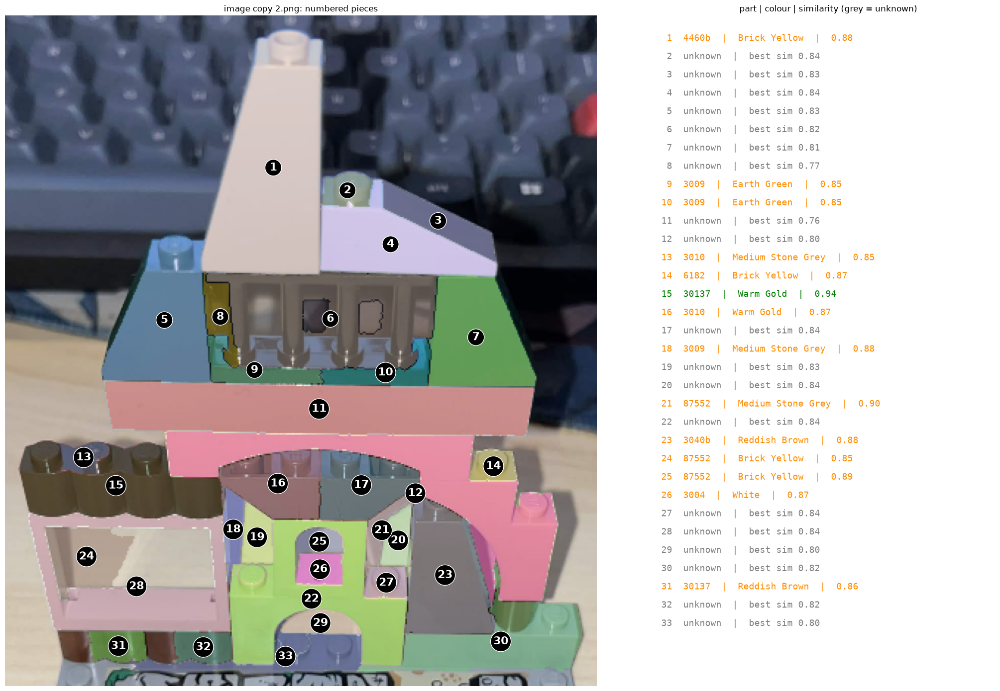

image copy 3.png: 27 pieces | named 10, unknown 17 | similarity median 0.84 | repeated part+colour: {(np.str_('3010'), np.str_('26')): 2}


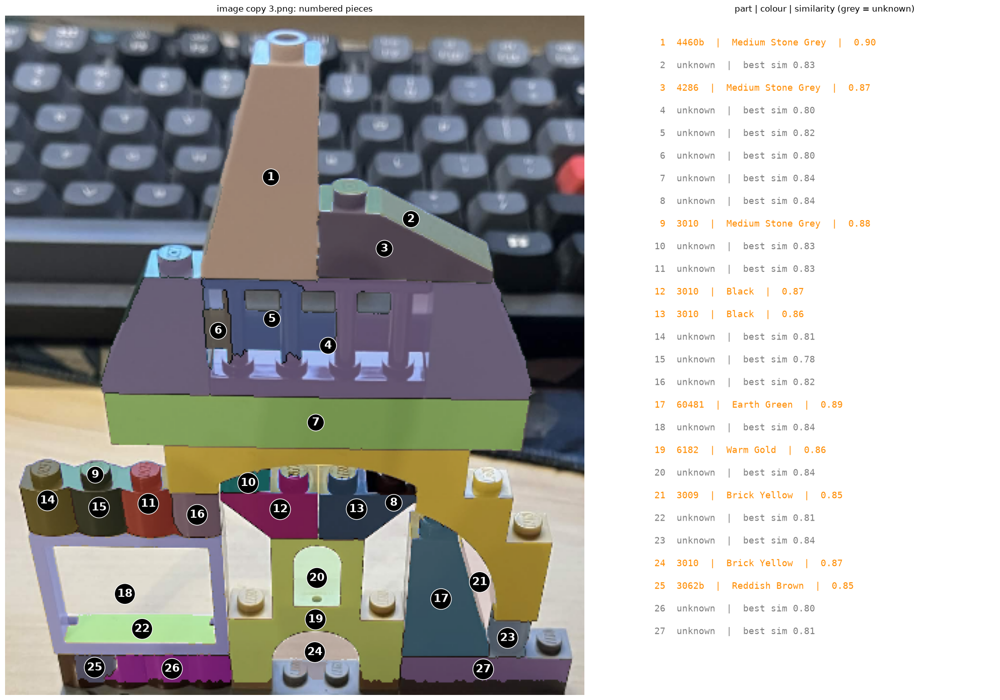

image copy.png: 33 pieces | named 14, unknown 19 | similarity median 0.84 | repeated part+colour: {(np.str_('3009'), np.str_('141')): 2, (np.str_('87552'), np.str_('5')): 2}


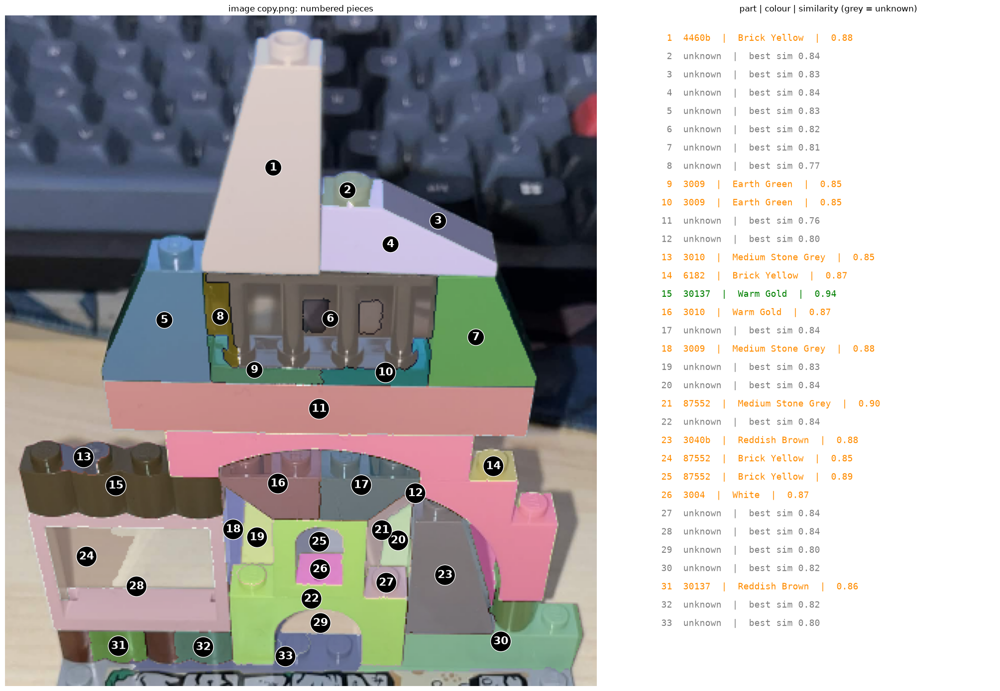

image.png: 31 pieces | named 11, unknown 20 | similarity median 0.83 | repeated part+colour: {(np.str_('4460b'), np.str_('1')): 3}


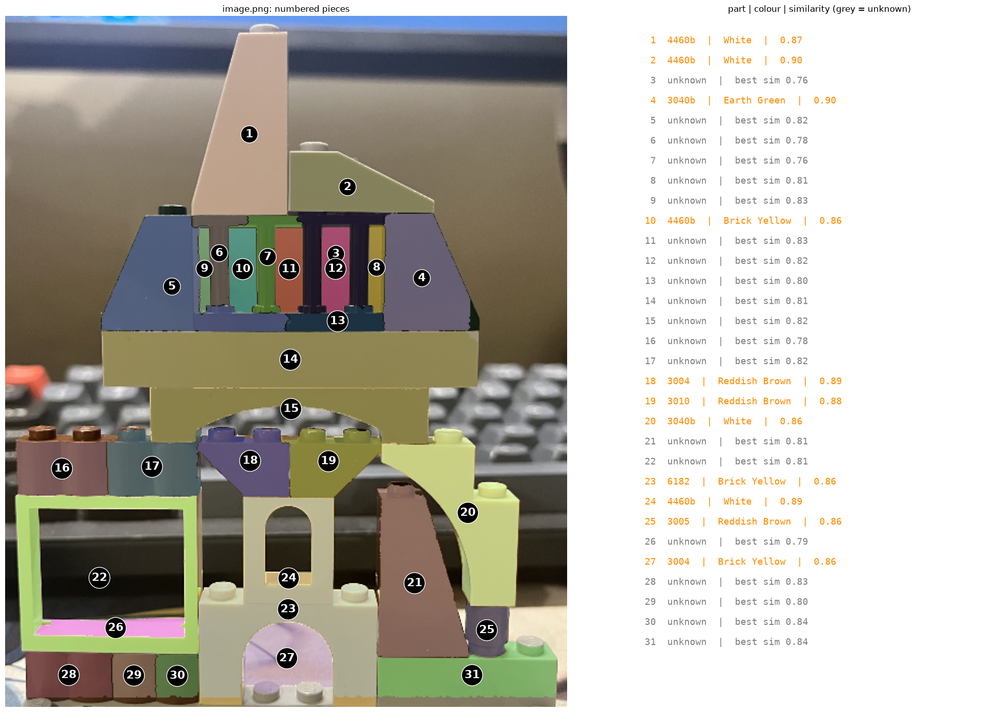

In [8]:
# 2e. RECOGNIZE: name every piece the pipeline found, with the lookup (fingerprint gallery of real photos + colour from Lab). Run after 2c.
# Each piece is cut out by its mask (grey elsewhere), embedded, matched to the gallery; colour is read from the mask pixels.
# OPEN SET on purpose: pieces outside set 21205 must stay addable (add_photos), so there is no inventory cap and closed_set is OFF
# (closed_set would restrict a piece's colour to the colours seen with its predicted shape, which blocks new colours and forces wrong colours after a wrong shape).
# Output: numbered pieces on the zoomed photo + a colour-coded list (green >= 0.93, orange 0.85-0.93, red < 0.85, grey = unknown).
# Repeats (same part+colour named more than once) are only REPORTED, not removed: they usually mean one brick was split into fragments (see 2f) or the gallery lacks wall-face views.
import csv, sys; sys.path.insert(0, '.'); import lego_lookup as L
from collections import Counter
RECT['image copy 3.png'] = (0.25, 0.0, 0.66, 0.64)   # this photo's chimney tip reaches the top edge
emb, gal = L.load_embedder(), L.load_gallery()
cname = {r['lego_id']: r['lego_name'] for r in csv.DictReader(open('data/lego_colors.csv'))}
MIN_PIECE = 400   # px at 1000 px wide; smaller pieces are not named
MIN_SIM = 0.85    # below this a piece is 'unknown'. shortcut: display cutoff, not calibrated; lego_lookup's own open-set cutoff is 0.977 (tuned on same-session photos, so everything on a real tower would be unknown). Calibrate on real wall crops. -1 = never unknown.

for f in sorted(glob.glob('real/*.[jJpP][pPnN]*[gG]')):
    name = os.path.splitext(os.path.basename(f))[0].replace(' ', '_'); rects = RECT.get(os.path.basename(f), RECT['default'])
    im = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); im = cv2.resize(im, (1000, int(1000 * im.shape[0] / im.shape[1])))
    fg = foreground_v2(im, rects); lab, _ = separate_v2(im, fg); pred = cleanup(lab)
    ids, crops, boxes = [], [], []
    for i in range(1, pred.max() + 1):
        m = pred == i
        if m.sum() < MIN_PIECE: continue
        ys, xs = np.where(m); bx = (xs.min(), ys.min(), xs.max(), ys.max()); mm = L.crop_box(m.astype(np.uint8) * 255, *bx) > 127
        crops.append(np.where(mm[..., None], L.crop_box(im, *bx), 127).astype(np.uint8)); ids.append(i); boxes.append((xs.mean(), ys.mean()))
    res = L.recognize(gal, L.embed(emb, crops), np.array([L.brick_lab(c) for c in crops]), closed_set=False, shape_min_sim=MIN_SIM)
    sims = np.array([r[1] for r in res]); named = [r for r in res if r[0] != 'unknown']
    rep = {k: v for k, v in Counter((r[0], r[2]) for r in named).items() if v > 1}
    print(f'{os.path.basename(f)}: {len(ids)} pieces | named {len(named)}, unknown {len(res) - len(named)} | similarity median {np.median(sims):.2f} | repeated part+colour: {rep or "none"}')
    over = im.copy(); rng = np.random.default_rng(0)
    for i in ids: over[pred == i] = (0.55 * over[pred == i] + 0.45 * rng.integers(40, 255, 3)).astype(np.uint8)
    ys_, xs_ = np.where(fg); y0, y1, x0, x1 = max(ys_.min() - 10, 0), ys_.max() + 10, max(xs_.min() - 10, 0), xs_.max() + 10   # zoom on the tower
    fig, (ax, tx) = plt.subplots(1, 2, figsize=(22, 14), gridspec_kw={'width_ratios': [3, 1.3]}); ax.imshow(over[y0:y1, x0:x1]); ax.axis('off'); tx.axis('off')
    for n, (cx, cy) in enumerate(boxes, 1): ax.text(cx - x0, cy - y0, str(n), color='white', fontsize=16, fontweight='bold', ha='center', va='center', bbox=dict(boxstyle='circle,pad=0.25', fc='black', ec='white'))
    for n, (shape, sim, col, _) in enumerate(res, 1):
        txt = f'{n:>2}  unknown  |  best sim {sim:.2f}' if shape == 'unknown' else f'{n:>2}  {shape}  |  {cname.get(col, col)}  |  {sim:.2f}'
        tx.text(0, 1 - n * 0.9 / max(len(res), 1), txt, fontsize=13, family='monospace', va='top', color='gray' if shape == 'unknown' else 'green' if sim >= .93 else 'darkorange' if sim >= .85 else 'red', transform=tx.transAxes)
    ax.set_title(f'{os.path.basename(f)}: numbered pieces'); tx.set_title('part | colour | similarity (grey = unknown)'); plt.tight_layout()
    fig.savefig(f'output/{name}_recognized.png', dpi=80, bbox_inches='tight'); plt.show()

**Result:** 27-33 pieces per photo, of which only 10-14 are named and the rest are unknown (median similarity 0.84). A part+color named twice usually means one brick was split into fragments.

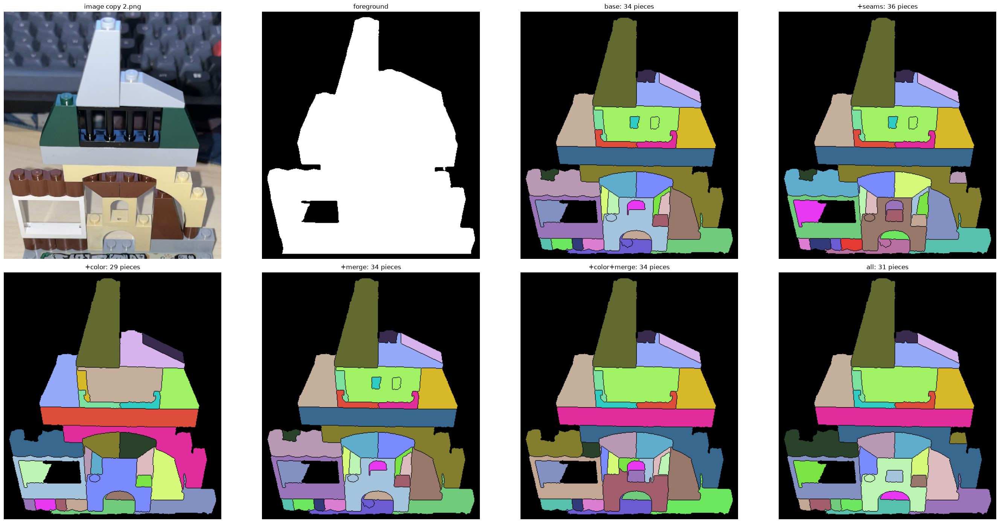

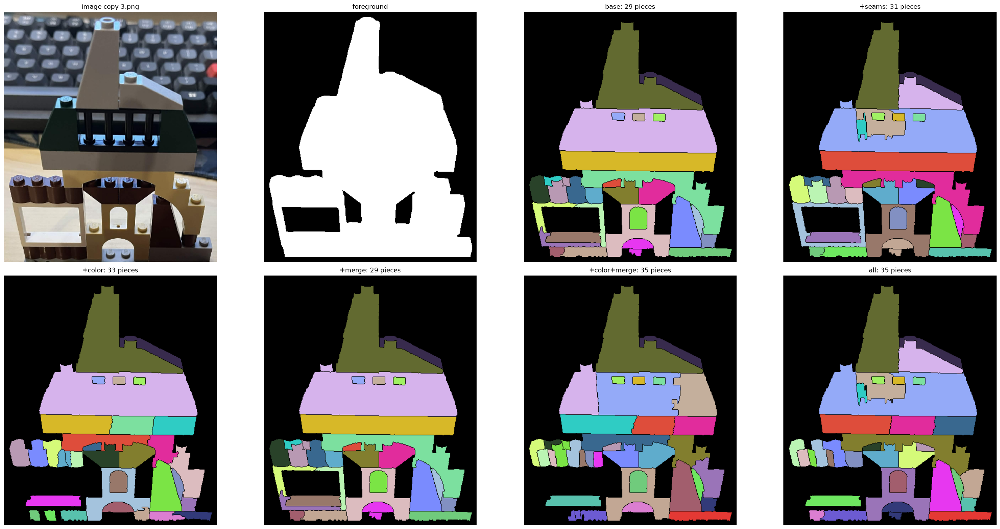

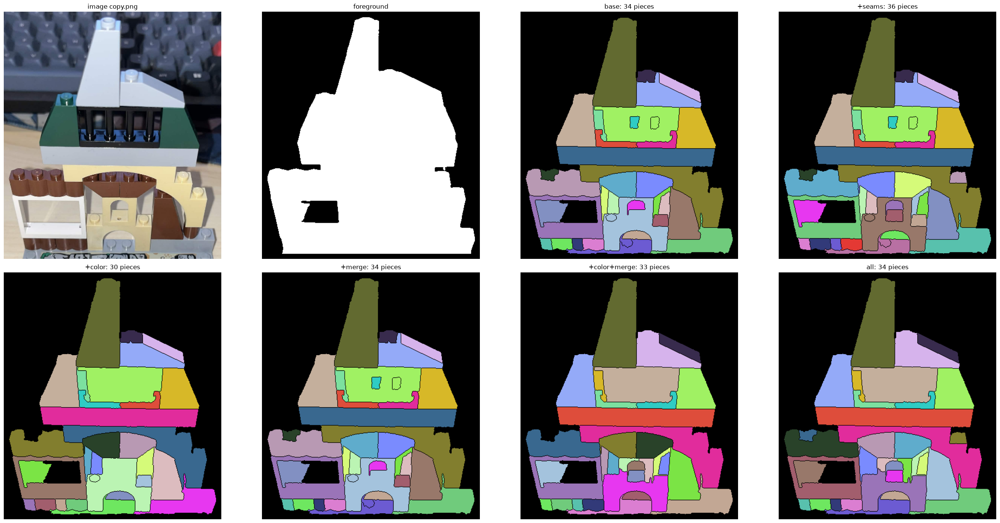

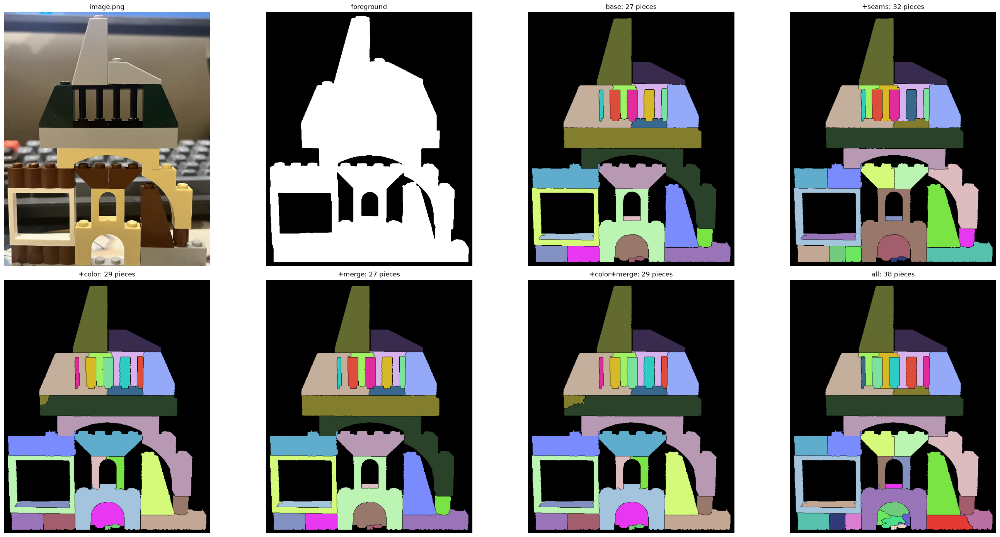

In [9]:
# 2f. IMPROVE THE SEPARATION on the REAL photos only (no renders, no cell 1, no score). Needs the imports cell, cell 2, 2b (cleanup, RECT) and 2c (foreground_v2, seam_lines).
# New cues on top of the edge map, each switchable, drawn side by side per photo so you can see what each one does:
#  color : k-means on the tower's Lab colours; where the colour cluster changes there is a boundary (dark green | black | grey have weak edges but different colours).
#  merge : after watershed, merge neighbours with a similar mean colour AND a weak edge between them (fixes over-splitting by shading, glare and print).
#  seams : the straight horizontal/vertical Hough lines from 2c.
def color_cut(im, fg, K=8):
    lab = cv2.cvtColor(cv2.bilateralFilter(im, 9, 40, 9), cv2.COLOR_RGB2LAB).astype(np.float32); w = np.array([0.6, 1, 1], np.float32)   # lightness counts less (shading)
    pts = lab[fg > 0]
    if len(pts) < K * 50: return np.zeros(fg.shape, np.uint8)
    sub = (pts[np.random.default_rng(0).choice(len(pts), min(20000, len(pts)), replace=False)] * w).astype(np.float32)
    _, _, centers = cv2.kmeans(sub, K, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0), 2, cv2.KMEANS_PP_CENTERS)
    lbl = ((lab.reshape(-1, 1, 3) * w - centers[None]) ** 2).sum(2).argmin(1).reshape(fg.shape).astype(np.uint8)
    return (cv2.morphologyEx(cv2.medianBlur(lbl, 5), cv2.MORPH_GRADIENT, K3) > 0).astype(np.uint8) * 255

def merge_regions(lab, im, edges, dE=12, thr=0.3):
    """Merge neighbouring regions whose mean Lab colours are within dE and whose shared border is less than `thr` edge pixels."""
    lm = cv2.cvtColor(im, cv2.COLOR_RGB2LAB).astype(np.float32); n = int(lab.max()) + 1; cnt = np.bincount(lab.ravel(), minlength=n).astype(np.float32)
    mean = np.stack([np.bincount(lab.ravel(), weights=lm[..., c].ravel(), minlength=n) / np.maximum(cnt, 1) for c in range(3)], 1); e = edges > 0; keys, eds = [], []
    for A, B, E in ((lab[:, :-1], lab[:, 1:], e[:, :-1] | e[:, 1:]), (lab[:-1], lab[1:], e[:-1] | e[1:])):
        m = (A != B) & (A > 0) & (B > 0); keys.append(np.minimum(A[m], B[m]).astype(np.int64) * n + np.maximum(A[m], B[m])); eds.append(E[m])
    if not keys or sum(len(k) for k in keys) == 0: return lab
    uk, inv = np.unique(np.concatenate(keys), return_inverse=True); tot = np.bincount(inv); es = np.bincount(inv, weights=np.concatenate(eds)); parent = np.arange(n)
    def find(x):
        while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for k, t, s in zip(uk, tot, es):
        a, b = divmod(int(k), n)
        if s / t < thr and np.linalg.norm(mean[a] - mean[b]) < dE: parent[find(a)] = find(b)
    out = np.array([find(i) for i in range(n)])[lab]; u, inv2 = np.unique(out, return_inverse=True)
    return (inv2.reshape(lab.shape) + (0 if u[0] == 0 else 1)).astype(np.int32)

def separate_x(im, fg, seam=False, color=False, merge=False, erode=2, min_seed=40):
    e = edge_map(im)
    if seam: v, hz = seam_lines(im, fg); e = e | v | hz
    if color: e = e | color_cut(im, fg)
    edges = cv2.dilate(e, K3); core = cv2.erode(((fg > 0) & (edges == 0)).astype(np.uint8), K3, iterations=erode)
    n, seeds = cv2.connectedComponents(core); area = np.bincount(seeds.ravel(), minlength=n)
    markers = np.zeros(fg.shape, np.int32); markers[cv2.erode((fg == 0).astype(np.uint8), K3, iterations=2) > 0] = 1; k = 2
    for i in range(1, n):
        if area[i] >= min_seed: markers[seeds == i] = k; k += 1
    cv2.watershed(im[..., ::-1].copy(), markers); out = np.where((markers >= 2) & (fg > 0), markers - 1, 0).astype(np.int32)
    return merge_regions(out, im, edges) if merge else out

def colorize(lab, seed=0):   # cell 4 redefines colorize with one argument; this is the 2b version again
    lut = np.random.default_rng(seed).integers(40, 255, (int(lab.max()) + 1, 3)); lut[0] = 0; return lut[lab].astype(np.uint8)

VARIANTS = {'base': {}, '+seams': dict(seam=True), '+color': dict(color=True), '+merge': dict(merge=True), '+color+merge': dict(color=True, merge=True), 'all': dict(seam=True, color=True, merge=True)}
for f in sorted(glob.glob('real/*.[jJpP][pPnN]*[gG]')):
    name = os.path.splitext(os.path.basename(f))[0].replace(' ', '_')
    im = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); im = cv2.resize(im, (1000, int(1000 * im.shape[0] / im.shape[1]))); fg = foreground_v2(im, RECT.get(os.path.basename(f), RECT['default']))
    ys, xs = np.where(fg); y0, y1, x0, x1 = max(ys.min() - 10, 0), ys.max() + 10, max(xs.min() - 10, 0), xs.max() + 10   # zoom on the tower
    fig, ax = plt.subplots(2, 4, figsize=(28, 14)); ax = ax.ravel(); ax[0].imshow(im[y0:y1, x0:x1]); ax[0].set_title(os.path.basename(f)); ax[1].imshow(fg[y0:y1, x0:x1], cmap='gray'); ax[1].set_title('foreground')
    for a, (vn, kw) in zip(ax[2:], VARIANTS.items()):
        pr = cleanup(separate_x(im, fg, **kw)); a.imshow(colorize(pr)[y0:y1, x0:x1]); a.set_title(f'{vn}: {pr.max()} pieces')
        cv2.imwrite(f'output/{name}_sep_{vn.strip("+").replace("+", "_")}.png', colorize(pr)[..., ::-1])
    for a in ax: a.axis('off')
    plt.tight_layout(); fig.savefig(f'output/{name}_separation_variants.png', dpi=60, bbox_inches='tight'); plt.show()

**Result:** One column per extra cue (color clusters, region merging, straight seams). Compare them to see which one separates bricks without over-splitting.

Score both stages on the rendered scenes. In `oracle` mode stage 2 gets the true foreground, so its score measures stage 2 alone.

In [10]:
# 3. Measure. Same scenes, 3 backgrounds. 'oracle' = true foreground given to stage 2, so its score is stage 2 alone.
def score(pred, gt):
    P, G = int(pred.max()) + 1, int(gt.max()) + 1
    mat = np.bincount((pred.astype(np.int64) * G + gt).ravel(), minlength=P * G).reshape(P, G)
    pa, ga = mat.sum(1), mat.sum(0); iou = mat / np.maximum(pa[:, None] + ga[None] - mat, 1); iou[0] = 0; iou[:, 0] = 0
    gv, pv = ga >= 150, pa >= 50; gv[0] = pv[0] = False
    m = (iou > .5) & pv[:, None] & gv[None]; tp = int(m.sum()); fp, fn = int(pv.sum()) - tp, int(gv.sum()) - tp
    sq = float(iou[m].mean()) if tp else 0.; rq = tp / max(tp + .5 * fp + .5 * fn, 1e-9)
    merges = int(((mat[pv][:, gv] / ga[gv] > .5).sum(1) >= 2).sum())   # a predicted blob that covers most of 2+ real bricks
    fgiou = ((pred > 0) & (gt > 0)).sum() / max(((pred > 0) | (gt > 0)).sum(), 1)
    return dict(fg_iou=fgiou, PQ=sq * rq, SQ=sq, RQ=rq, merges=merges, n_pred=int(pv.sum()), n_true=int(gv.sum()))

def evaluate(fn_fg=foreground, fn_sep=separate):
    print(f'{"bg":6} {"mode":7} {"fgIoU":>6} {"PQ":>6} {"SQ":>6} {"RQ":>6} {"merges":>7} {"pred":>6} {"true":>6}')
    for name, sc in SCENES.items():
        for mode in ('full', 'oracle'):
            rows = [score(fn_sep(im, fn_fg(im) if mode == 'full' else (gt > 0).astype(np.uint8)), gt) for im, gt in sc]
            m = {k: np.mean([r[k] for r in rows]) for k in rows[0]}
            print(f'{name:6} {mode:7} {m["fg_iou"]:6.3f} {m["PQ"]:6.3f} {m["SQ"]:6.3f} {m["RQ"]:6.3f} {m["merges"]:7.1f} {m["n_pred"]:6.1f} {m["n_true"]:6.1f}')
evaluate()

bg     mode     fgIoU     PQ     SQ     RQ  merges   pred   true
gray   full     0.676  0.228  0.826  0.275     5.2   36.8   38.2
gray   oracle   0.875  0.299  0.823  0.363     4.9   30.8   38.2
green  full     0.730  0.237  0.805  0.292     5.4   39.8   38.2
green  oracle   0.902  0.290  0.810  0.356     5.2   29.9   38.2
blue   full     0.735  0.240  0.821  0.291     5.6   38.2   38.2
blue   oracle   0.910  0.301  0.813  0.369     5.2   28.8   38.2


**Result:** The foreground is decent (IoU 0.68-0.74, 0.88-0.91 in oracle mode), but brick separation is weak: PQ is only about 0.23-0.30, with about 5 merges per tower. Gray is the hardest background, and stage 2 is the bottleneck.

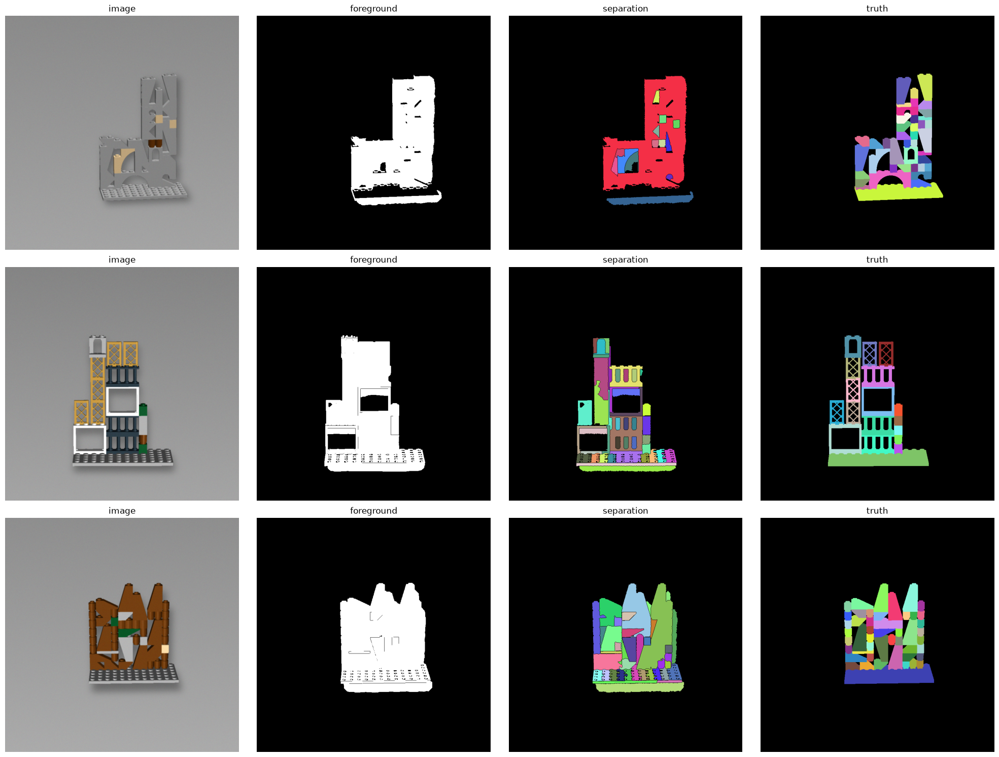

In [11]:
# 4. Look at it: image | foreground | separation | truth, for 3 scenes on the gray background (the hardest one: light-gray bricks)
BG = 'gray'
fig, ax = plt.subplots(3, 4, figsize=(20, 15)); rng = np.random.default_rng(1)
def colorize(lab):
    out = np.zeros(lab.shape + (3,), np.uint8); lut = rng.integers(40, 255, (lab.max() + 1, 3)); lut[0] = 0; return lut[lab].astype(np.uint8)
for row, (im, gt) in zip(ax, SCENES[BG][:3]):
    fg = foreground(im); pred = separate(im, fg)
    for a, x, t in zip(row, (im, fg * 255, colorize(pred), colorize(gt)), ('image', 'foreground', 'separation', 'truth')): a.imshow(x, cmap='gray'); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

# real photos taken the new way (plain background, camera on a stand): drop them in real/plain/ and rerun this cell. No truth, so look at them.
import glob
for f in sorted(glob.glob('real/plain/*.[jJpP][pPnN]*[gG]')):
    im = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); im = cv2.resize(im, (1000, int(1000 * im.shape[0] / im.shape[1])))
    fg = foreground(im); pred = separate(im, fg); fig, a = plt.subplots(1, 3, figsize=(21, 7))
    for x, t, y in zip((im, fg * 255, colorize(pred)), ('image', 'foreground', f'{pred.max()} bricks'), a): y.imshow(x, cmap='gray'); y.set_title(t); y.axis('off')
    plt.show()

**Result:** Image, foreground, separation and truth side by side on the gray background. Photos dropped into `real/plain/` are shown below them.

Shut the kernel down, so GPU and RAM are freed after Run All.

In [ ]:
get_ipython().kernel.do_shutdown(False)   # last cell: kills this kernel so GPU/RAM is freed after Run All

{'status': 'ok', 'restart': False}

: 

## Conclusion
Finding the tower works reasonably well, especially with BiRefNet. Splitting it into single bricks with edges and watershed is the weak stage: about 0.3 panoptic quality even with a perfect foreground, and several merged bricks per tower. Color clusters and region merging help in places, but don't close the gap. Learned segmentation (`tower_seg.ipynb`) separates bricks better, and both approaches still depend on the lookup for naming, which is the bottleneck on real towers.